# 04 Explainability for unsupervised learning

## Step 9: Why did customers end up in these clusters?

**XAI** (explainable AI) means tools that show *why* a model gave its answer. KMeans has no built-in "feature importance", because it never predicted anything from labels. So we use four indirect methods:

1. **Surrogate model.** We train a supervised model (a Random Forest) to *predict the cluster label* from the customer's features. If it predicts well, the clusters can be described by simple rules on the features.
2. **SHAP** (SHapley Additive exPlanations). For each customer and each feature, SHAP gives a number that says how much that feature pushed the surrogate towards a cluster. It is based on fair-share ideas from game theory.
3. **Distance contributions.** KMeans assigns a customer to the nearest cluster centre. We split that distance feature by feature to see which features pull a customer towards their own centre. This one explains KMeans directly.
4. **Permutation importance.** Shuffle one feature at a time and see how much the surrogate's accuracy drops. A big drop means the feature matters. It is a cross-check on SHAP.

**Limitation to keep in mind:** these tools explain the clusters *the model found* and the *surrogate's behaviour*. They do not reveal a hidden truth about customers. We report how faithful the surrogate is (its *fidelity*) so you know how far to trust them.

**What this cell does:** Loads the original-unit data (11 clustering features), the cluster labels, the cluster names, the scaled data and the saved KMeans model.  
**What to look for:** 11 feature columns, 8,950 rows, and six cluster names.  
**What the output means:** We use the features in their original dollar units for the surrogate, so every explanation later reads in real money. Tree models are not affected by log or scaling (they only compare 'bigger than', not distances), so this does not change which splits they find.

In [1]:
# Imported here so this step only loads the libraries when it runs
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the current folder until we see pyproject.toml (nbconvert runs inside notebooks/)."""
    return next(folder for folder in [start, *start.parents] if (folder / "pyproject.toml").exists())


ROOT = find_project_root()
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
RANDOM_STATE = 42

scaled = pd.read_csv(PROCESSED_DIR / "credit_card_scaled.csv", index_col=0)
imputed_original = pd.read_csv(PROCESSED_DIR / "credit_card_imputed_original_units.csv", index_col=0)
labels = pd.read_csv(PROCESSED_DIR / "cluster_labels.csv", index_col=0)["cluster"]
cluster_names = {int(key): value for key, value in json.loads((PROCESSED_DIR / "cluster_names.json").read_text()).items()}
kmeans_model = joblib.load(PROCESSED_DIR / "kmeans_k6.joblib")

features = scaled.columns.tolist()          # same 11 columns, same order the model was trained on
original_units = imputed_original[features]  # the same 11 features, in dollars and counts
print(f"{original_units.shape=}, {labels.shape=}")
print(cluster_names)

original_units.shape=(8950, 11), labels.shape=(8950,)
{0: 'Newer customers, small limit, mixed use', 1: 'Steady everyday spenders', 2: 'Frequent buyers, pay in full', 3: 'Big spenders, high limit, carry a balance', 4: 'Cash advance borrowers', 5: 'Dormant, barely used card'}


### 1. Surrogate model

We split customers into a **training set** (75%) to build the surrogate and a **test set** (25%) it has never seen. Accuracy on the test set is the honest measure of how well the clusters can be recreated from the features. `stratify` keeps the same cluster proportions in both parts.

We also run **cross-validation**: the data is split into 5 parts, and the model is trained on 4 and tested on the 5th, five times in turn. If the five scores are similar, the result does not depend on one lucky split.

**What this cell does:** Splits the customers, trains a Random Forest to predict the cluster, and reports test accuracy, 5-fold cross-validated accuracy and a per-cluster report.  
**What to look for:** Accuracy far above the 'always guess the biggest cluster' baseline (26.9%), and which clusters have lower recall (the share of that cluster's customers the model found).  
**What the output means:** High accuracy means the clusters are easy to describe with the features, so explanations based on the surrogate are trustworthy. Low accuracy would be a warning: the explanations would be describing something the surrogate itself cannot reproduce.

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    original_units, labels, test_size=0.25, stratify=labels, random_state=RANDOM_STATE)

surrogate = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)
surrogate.fit(X_train, y_train)

test_accuracy = surrogate.score(X_test, y_test)  # accuracy on customers the model has never seen
baseline = labels.value_counts(normalize=True).max()  # what 'always guess the biggest cluster' would score
cv_scores = cross_val_score(
    RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    original_units, labels, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="accuracy")
print(f"{test_accuracy=:.3f}  {baseline=:.3f}")
print(f"{cv_scores.round(3)=}  mean={cv_scores.mean():.3f}  std={cv_scores.std():.3f}")
print(classification_report(y_test, surrogate.predict(X_test), target_names=[cluster_names[c] for c in sorted(cluster_names)], digits=3))

test_accuracy=0.950  baseline=0.269
cv_scores.round(3)=array([0.954, 0.958, 0.951, 0.945, 0.946])  mean=0.951  std=0.005
                                           precision    recall  f1-score   support

  Newer customers, small limit, mixed use      0.922     0.946     0.934       149
                 Steady everyday spenders      0.933     0.951     0.942       513
             Frequent buyers, pay in full      0.955     0.949     0.952       312
Big spenders, high limit, carry a balance      0.951     0.941     0.946       409
                   Cash advance borrowers      0.975     0.970     0.972       601
                Dormant, barely used card      0.940     0.921     0.930       254

                                 accuracy                          0.950      2238
                                macro avg      0.946     0.946     0.946      2238
                             weighted avg      0.951     0.950     0.950      2238



**What this cell does:** Shows the confusion matrix of the surrogate on the test customers.  
**What to look for:** Strong values on the diagonal, and which pairs of clusters get mixed up (off-diagonal cells).  
**What the output means:** Rows are the true cluster, columns what the surrogate predicted. Confusion between two clusters means they sit next to each other in feature space, which agrees with the touching clouds we saw in PCA.

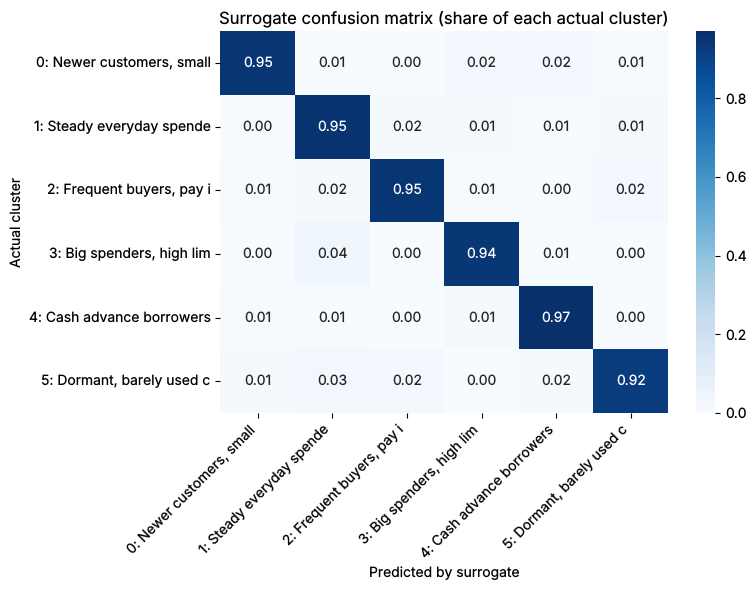

In [3]:
import matplotlib.pyplot as plt  # imported here because plotting starts in this cell
import seaborn as sns
from sklearn.metrics import confusion_matrix

matrix = confusion_matrix(y_test, surrogate.predict(X_test), normalize="true")  # each row sums to 1
short_names = [f"{c}: {cluster_names[c][:22]}" for c in sorted(cluster_names)]
plt.figure(figsize=(8, 6))
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="Blues", xticklabels=short_names, yticklabels=short_names)
plt.xlabel("Predicted by surrogate"); plt.ylabel("Actual cluster")
plt.title("Surrogate confusion matrix (share of each actual cluster)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(FIGURES_DIR / "surrogate_confusion.png", dpi=110)
plt.show()

### What the surrogate tells us (and its fidelity)

- **Fidelity is high: 95.0% on customers it never saw** (cross-validated: 95.1%, folds between 94.5% and 95.8%), against a 26.9% baseline for always guessing the biggest cluster. In other words, the surrogate reproduces KMeans's cluster for 19 customers out of 20. Recall (how many of a cluster's members it found) ranges from 92.1% (dormant) to 97.0% (cash advance borrowers).
- **Where it goes wrong:** the top confusion is 17 big spenders (of 409) predicted as steady everyday spenders, followed by smaller mixes of the same neighbours. Mistakes happen between clusters that sit next to each other, which fits the touching clouds we saw in PCA.
- **How to read the 95%.** KMeans is itself a fixed rule on these same features (nearest centre), so a flexible model learning that rule is expected to do well. High accuracy tells us the clusters are *describable* with the features. It does **not** prove the clusters are meaningful or that customers truly fall into six types. A low score would have been the warning sign, and we do not have one.

### 2. SHAP

For each customer, SHAP splits the surrogate's prediction into one contribution per feature. For cluster *c*, a **positive** SHAP value means "this feature value pushed the model towards cluster *c*" and a **negative** one means it pushed away. Contributions are in the model's probability units. We explain the **test customers** (never used to train the surrogate).

`shap.TreeExplainer` is the fast, exact method for tree models such as a Random Forest.

**What this cell does:** Computes SHAP values for the test customers and prints the shape of the result.  
**What to look for:** The shape should be (customers, features, clusters) = (about 2,238, 11, 6).  
**What the output means:** Each customer has one SHAP value per feature per cluster. The third axis is the cluster, which we need for the plots below.

In [4]:
import shap  # imported here because SHAP is slow to load and only needed from this step on

explainer = shap.TreeExplainer(surrogate)                    # exact explanations for tree ensembles
shap_values = explainer(X_test, check_additivity=False)      # an Explanation object; skip the slow additivity check
print(f"{shap_values.values.shape=}  (customers, features, clusters)")

shap_values.values.shape=(2238, 11, 6)  (customers, features, clusters)


**What this cell does:** Draws the global SHAP summary: the average size of each feature's contribution, split by cluster.  
**What to look for:** Which features have the longest bars, and which colours (clusters) dominate each bar.  
**What the output means:** A long bar means the feature moves predictions a lot, on average. The colours show for which clusters it matters, so a feature may be vital for one cluster and irrelevant for the others.

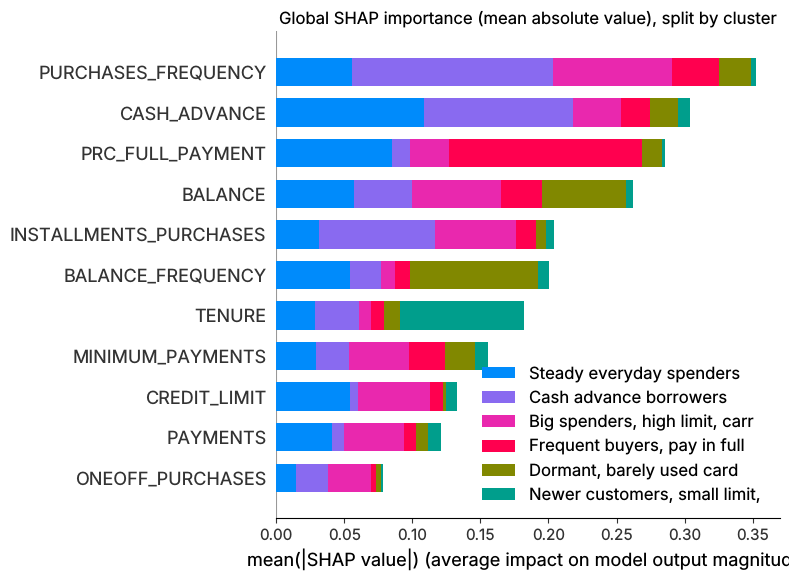

,"Newer customers, small limit, mixed use",Steady everyday spenders,"Frequent buyers, pay in full","Big spenders, high limit, carry a balance",Cash advance borrowers,"Dormant, barely used card",ALL CLUSTERS
PURCHASES_FREQUENCY,0.004,0.055,0.035,0.087,0.148,0.024,0.352
CASH_ADVANCE,0.009,0.109,0.021,0.035,0.109,0.020,0.304
PRC_FULL_PAYMENT,0.003,0.085,0.142,0.029,0.013,0.014,0.286
BALANCE,0.005,0.057,0.030,0.065,0.043,0.062,0.262
INSTALLMENTS_PURCHASES,0.006,0.031,0.014,0.060,0.086,0.007,0.204
BALANCE_FREQUENCY,0.008,0.054,0.011,0.010,0.023,0.094,0.200
TENURE,0.091,0.029,0.010,0.008,0.032,0.012,0.182
MINIMUM_PAYMENTS,0.010,0.029,0.026,0.044,0.024,0.022,0.156
CREDIT_LIMIT,0.008,0.054,0.009,0.053,0.006,0.002,0.133
PAYMENTS,0.010,0.041,0.009,0.044,0.009,0.009,0.121


In [5]:
plt.figure()
shap.summary_plot(
    shap_values.values, X_test, plot_type="bar", show=False,
    class_names=[cluster_names[c][:30] for c in sorted(cluster_names)])  # one coloured segment per cluster
plt.title("Global SHAP importance (mean absolute value), split by cluster")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_global_bar.png", dpi=110, bbox_inches="tight")
plt.show()

# The same numbers as a table: mean |SHAP| per feature (rows) and cluster (columns)
mean_abs_shap = pd.DataFrame(
    np.abs(shap_values.values).mean(axis=0), index=features, columns=[cluster_names[c] for c in sorted(cluster_names)])
mean_abs_shap["ALL CLUSTERS"] = mean_abs_shap.sum(axis=1)
mean_abs_shap.sort_values("ALL CLUSTERS", ascending=False).round(3)

**What this cell does:** Draws a beeswarm SHAP plot for the cluster with the most distinctive profile (the 'big spenders'), so we can see direction as well as size.  
**What to look for:** Each dot is a customer. Red means a high feature value, blue a low one. Dots to the right pushed towards this cluster.  
**What the output means:** This shows direction: for example, red dots on the right for BALANCE means a high balance pushes a customer into this cluster.

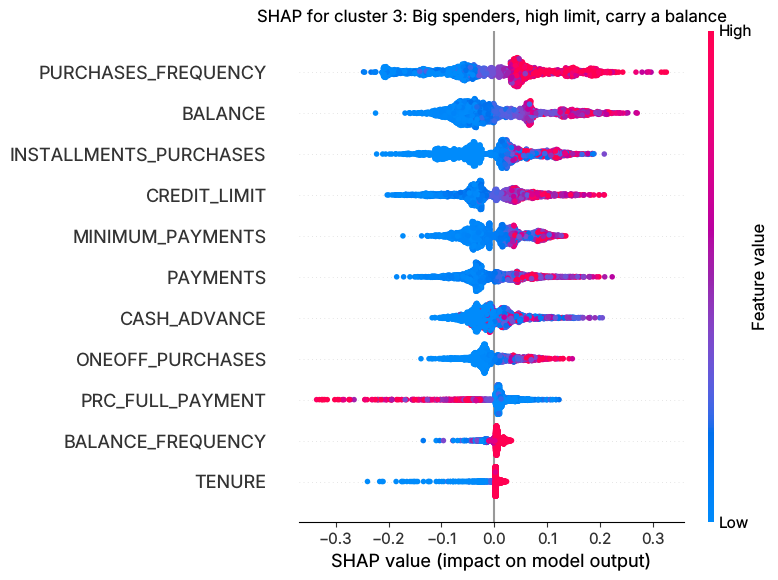

In [6]:
BIG_SPENDERS = 3  # cluster number from notebook 03 (named 'Big spenders, high limit, carry a balance')
plt.figure()
shap.plots.beeswarm(shap_values[:, :, BIG_SPENDERS], show=False, max_display=11)
plt.title(f"SHAP for cluster {BIG_SPENDERS}: {cluster_names[BIG_SPENDERS]}")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_beeswarm_cluster3.png", dpi=110, bbox_inches="tight")
plt.show()

**What this cell does:** Picks one typical customer from each cluster (the test customer closest to that cluster's centre) and draws a SHAP waterfall plot for each.  
**What to look for:** The bars show how each feature pushed the probability of the customer's own cluster up (red) or down (blue), starting from the average and ending at the model's final value f(x).  
**What the output means:** A waterfall explains one customer. Reading it top to bottom tells the story: 'this customer is in this cluster mainly because of these two or three features'. Feature values are shown in real units, as dollars or counts.

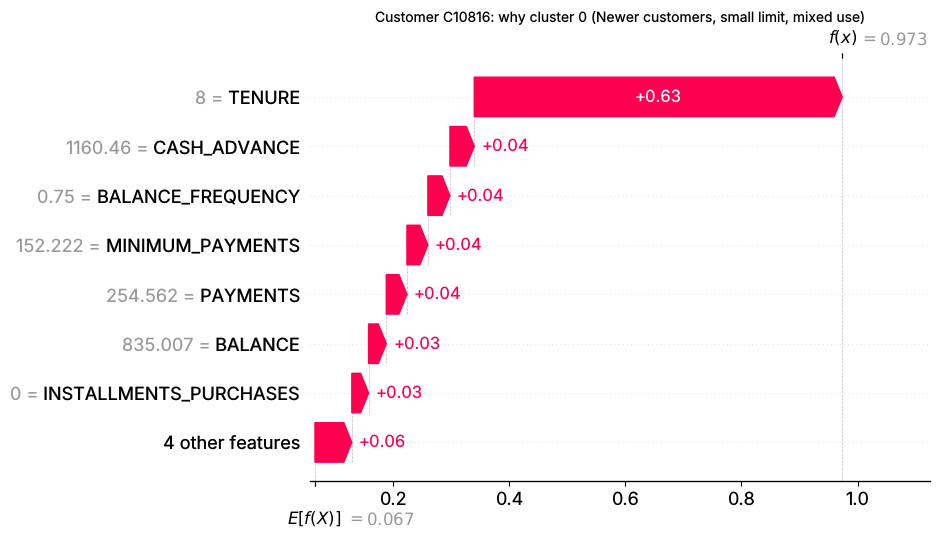

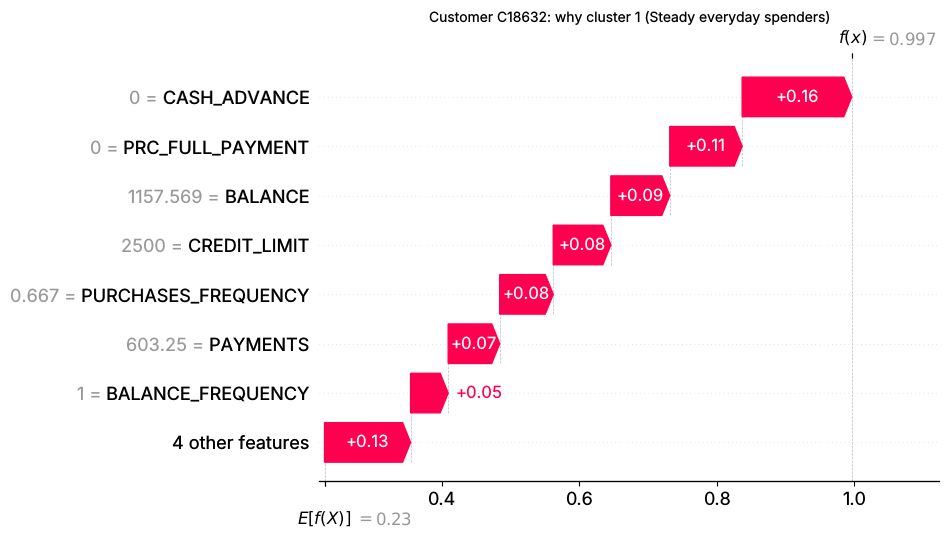

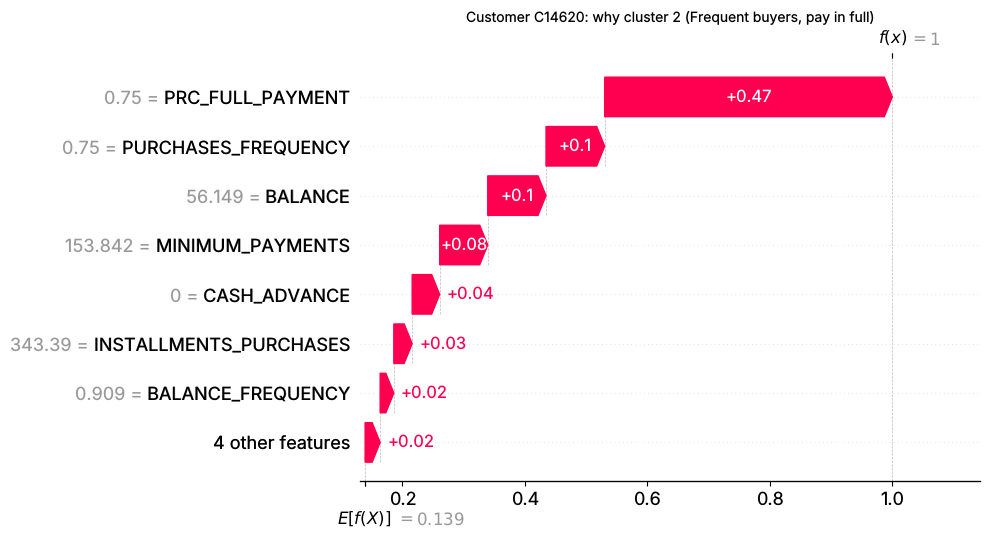

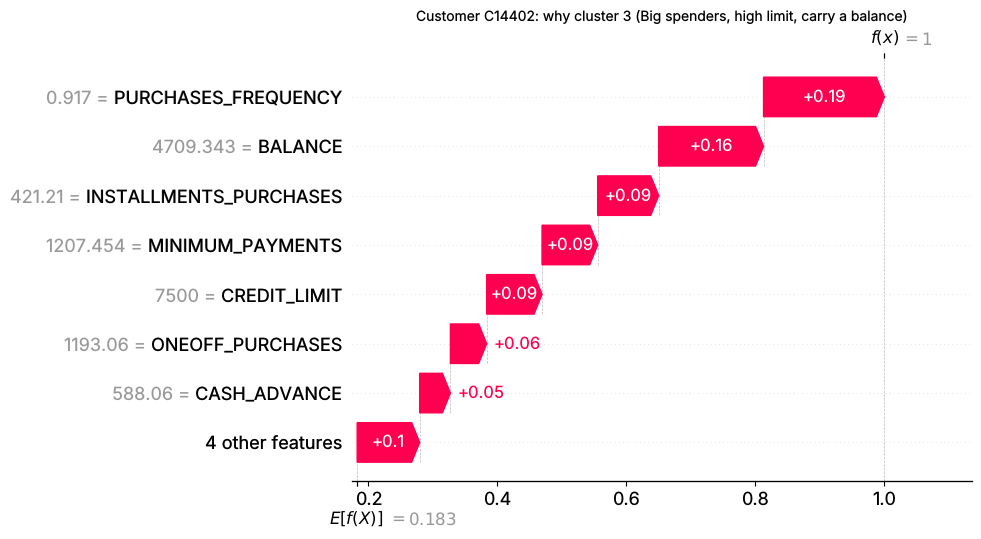

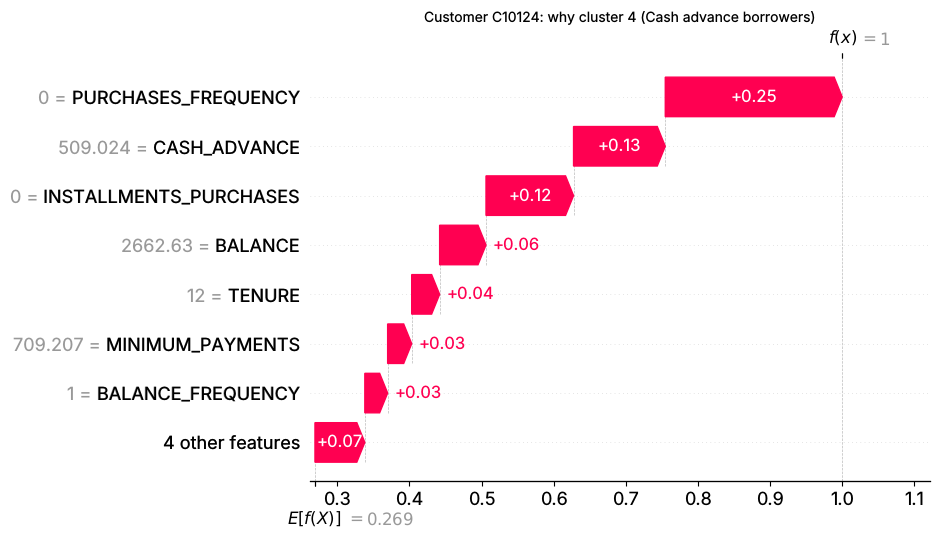

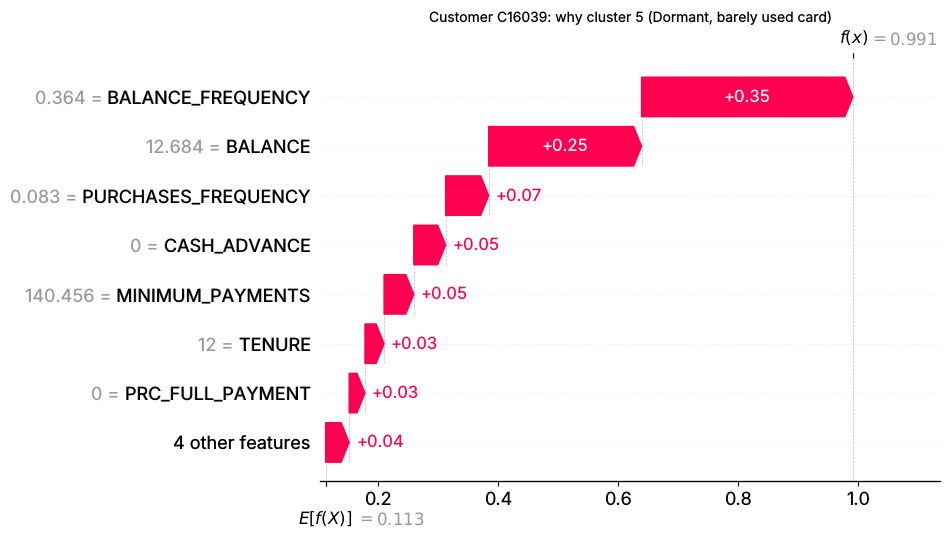

In [7]:
# Distance of each test customer to their own cluster centre, in the scaled space KMeans used
test_scaled = scaled.loc[X_test.index]
own_centres = kmeans_model.cluster_centers_[y_test.values]
distance_to_own_centre = pd.Series(np.linalg.norm(test_scaled.values - own_centres, axis=1), index=X_test.index)

for cluster in sorted(cluster_names):
    # the most typical member: the customer closest to the centre of their own cluster
    typical_customer = distance_to_own_centre[y_test == cluster].idxmin()
    row_position = X_test.index.get_loc(typical_customer)
    plt.figure()
    shap.plots.waterfall(shap_values[row_position, :, cluster], max_display=8, show=False)
    plt.title(f"Customer {typical_customer}: why cluster {cluster} ({cluster_names[cluster]})", fontsize=10)
    plt.savefig(FIGURES_DIR / f"shap_waterfall_cluster{cluster}.png", dpi=110, bbox_inches="tight")
    plt.show()

### What SHAP tells us

- **Global:** the features that move predictions most are `PURCHASES_FREQUENCY` (mean absolute SHAP 0.35), `CASH_ADVANCE` (0.30), `PRC_FULL_PAYMENT` (0.29) and `BALANCE` (0.26). `ONEOFF_PURCHASES` matters least (0.08): once we know *how often* someone buys, the size of their one-off purchases adds little.
- **Each cluster has its own signature feature:**
  - *Newer customers:* `TENURE` (0.09, versus about 0.03 or less for every other cluster).
  - *Frequent buyers, pay in full:* `PRC_FULL_PAYMENT` (0.14, the largest single value in their column).
  - *Dormant:* `BALANCE_FREQUENCY` and `BALANCE`.
  - *Cash advance borrowers:* `PURCHASES_FREQUENCY` (0.15), `CASH_ADVANCE` (0.11) and `INSTALLMENTS_PURCHASES` (0.09): no buying, but cash advances.
  - *Steady everyday spenders:* `CASH_ADVANCE` (the absence of it) and `PRC_FULL_PAYMENT`.
- **Waterfall plots, one typical customer per cluster** (the customer closest to the cluster centre). In every case the surrogate is 97% to 100% sure of the cluster, and the top drivers agree with the profile from Step 8:

| Cluster | Customer | Main drivers (feature value, push towards the cluster) |
|---|---|---|
| 0 Newer | C10816 | `TENURE` of 8 months (+0.63) |
| 1 Steady | C18632 | no `CASH_ADVANCE` (+0.16), `PRC_FULL_PAYMENT` of 0 (+0.11), balance 1,158 (+0.09) |
| 2 Pay in full | C14620 | `PRC_FULL_PAYMENT` of 0.75 (+0.47) |
| 3 Big spenders | C14402 | purchase frequency 0.92 (+0.19), balance 4,709 (+0.16), installments 421 (+0.09) |
| 4 Cash advance | C10124 | purchase frequency 0 (+0.25), cash advance 509 (+0.13), no installments (+0.12) |
| 5 Dormant | C16039 | `BALANCE_FREQUENCY` of 0.36 (+0.35), balance of 13 (+0.25) |

SHAP values here are in probability units, so "+0.47" means that feature alone added 47 percentage points to the probability of that cluster.

### 3. Distance contributions (direct explanation of KMeans)

KMeans puts each customer in the cluster whose centre is closest. The squared distance to a centre is the sum, over all 11 features, of (customer value minus centre value) squared. So we can split that distance **per feature**.

For each customer we compute, for every feature:

> **advantage = (squared gap to the nearest *other* centre) minus (squared gap to their *own* centre)**

A **positive** advantage means this feature makes the customer look more like their own cluster than like the runner-up. A **negative** one means this feature actually pulls them towards the other cluster. Adding up all 11 advantages gives the total reason the customer was assigned where they were. We average these by cluster.

**What this cell does:** Computes per-feature distance contributions for every customer and averages the advantage by cluster.  
**What to look for:** The sign check at the top (the smallest total advantage should be 0 or above) and the biggest positive values in each row of the table.  
**What the output means:** Large positive numbers show the features that really hold each cluster together. A feature that is near 0 does not help separate that cluster from its neighbour.

In [8]:
centres = kmeans_model.cluster_centers_                         # shape (6 clusters, 11 features)
customer_values = scaled.values                                 # shape (8950, 11)
own_cluster = labels.loc[scaled.index].values

# Squared gap to every centre, feature by feature: shape (customers, clusters, features)
squared_gap = (customer_values[:, None, :] - centres[None, :, :]) ** 2
total_distance = squared_gap.sum(axis=2)                        # squared distance to each centre

# Find each customer's nearest OTHER centre by hiding their own with infinity
distance_to_others = total_distance.copy()
distance_to_others[np.arange(len(scaled)), own_cluster] = np.inf
nearest_other = distance_to_others.argmin(axis=1)

rows = np.arange(len(scaled))
advantage = squared_gap[rows, nearest_other, :] - squared_gap[rows, own_cluster, :]  # (customers, features)
print(f"{advantage.sum(axis=1).min()=:.4f}  (should be 0 or above: every customer is nearest to their own centre)")

advantage_by_cluster = pd.DataFrame(advantage, columns=features, index=scaled.index).groupby(own_cluster).mean()
advantage_by_cluster.index = [f"{c}: {cluster_names[c]}" for c in advantage_by_cluster.index]
advantage_by_cluster.round(2)

advantage.sum(axis=1).min()=0.0031  (should be 0 or above: every customer is nearest to their own centre)


,BALANCE,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,BALANCE_FREQUENCY,PURCHASES_FREQUENCY,PRC_FULL_PAYMENT,TENURE
"0: Newer customers, small limit, mixed use",-0.40,0.00,-0.39,-0.36,0.28,0.14,-0.05,-0.25,-0.62,-0.62,12.20
1: Steady everyday spenders,0.02,0.30,-0.11,0.99,0.90,0.29,0.10,0.40,-0.20,0.88,0.03
"2: Frequent buyers, pay in full",0.54,-0.26,0.20,0.25,0.08,0.10,0.60,-0.23,0.20,5.61,-0.15
"3: Big spenders, high limit, carry a balance",0.56,0.75,0.71,0.16,1.36,0.72,0.64,0.01,0.72,0.01,-0.07
4: Cash advance borrowers,0.19,0.82,2.15,1.67,-0.38,-0.05,-0.07,-0.11,2.48,-0.01,-0.02
"5: Dormant, barely used card",2.42,0.11,0.09,-0.26,0.02,0.52,0.77,6.08,0.62,-0.18,-0.10


**What this cell does:** Draws the distance-contribution table as a heatmap.  
**What to look for:** Dark red cells: the feature strongly pulls members towards their own cluster. Blue cells: it pulls them towards the neighbouring cluster.  
**What the output means:** Compare with the SHAP importances. They answer slightly different questions (SHAP: what predicts the cluster; distance: what makes members close to their own centre), so agreement between them makes the story stronger.

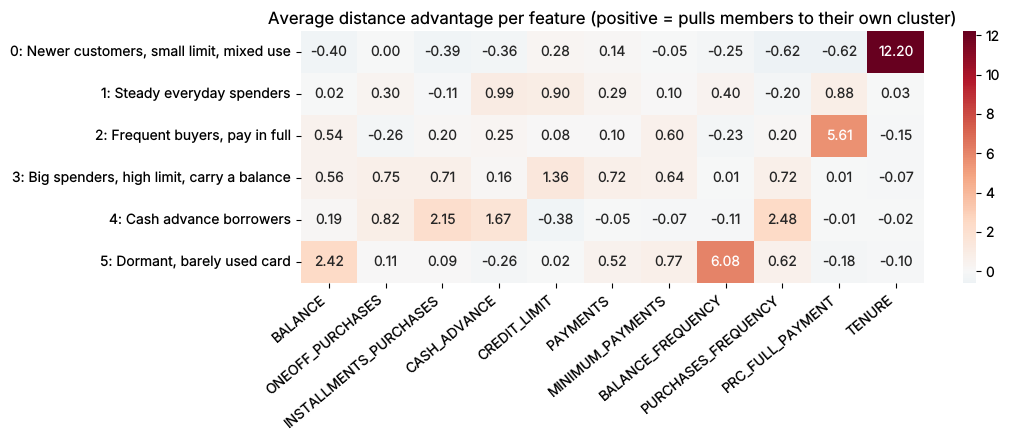

In [9]:
plt.figure(figsize=(11, 4.5))
sns.heatmap(advantage_by_cluster, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Average distance advantage per feature (positive = pulls members to their own cluster)")
plt.xticks(rotation=40, ha="right"); plt.tight_layout()
plt.savefig(FIGURES_DIR / "distance_contributions.png", dpi=110, bbox_inches="tight")
plt.show()

### What the distance contributions tell us

The biggest positive numbers in each row are the features that hold the cluster together. They match SHAP almost one for one:

- **Newer customers:** `TENURE` at **12.2**, by far the largest number in the table. On nearly every other feature these customers are closer to their neighbour, the cash advance cluster (negative values for spending, cash advance and payments). In practice this cluster is a **tenure group first** and a spending group second.
- **Frequent buyers, pay in full:** `PRC_FULL_PAYMENT` at **5.6**.
- **Dormant:** `BALANCE_FREQUENCY` at **6.1** and `BALANCE` at **2.4**.
- **Cash advance borrowers:** `PURCHASES_FREQUENCY` (2.5), `INSTALLMENTS_PURCHASES` (2.2) and `CASH_ADVANCE` (1.7).
- **Big spenders:** the pull is spread over many features at once (`CREDIT_LIMIT` 1.4, `ONEOFF_PURCHASES` 0.8, `PAYMENTS` 0.7, `PURCHASES_FREQUENCY` 0.7, `INSTALLMENTS_PURCHASES` 0.7). They are defined by a combination, not by one feature.
- **Steady everyday spenders:** no feature is above 1.0 (`CASH_ADVANCE` 1.0, `CREDIT_LIMIT` 0.9, `PRC_FULL_PAYMENT` 0.9). This is the most "ordinary" group. It is also the nearest neighbour for four of the other five clusters, so it sits in the middle of the map, which fits the 17 big spenders that the surrogate mistook for it.

### 4. Permutation importance (cross-check on SHAP)

Permutation importance shuffles one feature's values among the **test** customers, which breaks its link to the cluster, and measures how much accuracy falls. A big drop means the surrogate relied on that feature. A weakness: if two features carry the same information, shuffling one can look harmless because the other still covers for it, so correlated features can be understated.

**What this cell does:** Computes permutation importance on the test set (10 shuffles per feature) and puts it beside the SHAP ranking.  
**What to look for:** Whether the order of features is broadly the same in both columns, and the rank correlation at the bottom.  
**What the output means:** If two quite different methods give a similar ranking, we can trust the ranking more. Differences are worth a closer look, often because of correlated features.

In [10]:
from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance

permutation = permutation_importance(surrogate, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="accuracy", n_jobs=-1)
importance_table = pd.DataFrame({
    "permutation_drop_in_accuracy": permutation.importances_mean,   # average accuracy lost when this feature is shuffled
    "permutation_std": permutation.importances_std,
    "mean_abs_SHAP": mean_abs_shap["ALL CLUSTERS"],
}, index=features).sort_values("permutation_drop_in_accuracy", ascending=False)
importance_table["rank_permutation"] = importance_table["permutation_drop_in_accuracy"].rank(ascending=False).astype(int)
importance_table["rank_SHAP"] = importance_table["mean_abs_SHAP"].rank(ascending=False).astype(int)
display(importance_table.round(3))
rho = spearmanr(importance_table["permutation_drop_in_accuracy"], importance_table["mean_abs_SHAP"]).statistic
print(f"Rank agreement between permutation importance and SHAP (Spearman): {rho:.2f}")

,permutation_drop_in_accuracy,permutation_std,mean_abs_SHAP,rank_permutation,rank_SHAP
PURCHASES_FREQUENCY,0.172,0.005,0.352,1,1
PRC_FULL_PAYMENT,0.141,0.006,0.286,2,3
CASH_ADVANCE,0.112,0.004,0.304,3,2
TENURE,0.101,0.003,0.182,4,7
BALANCE_FREQUENCY,0.084,0.004,0.200,5,6
BALANCE,0.061,0.003,0.262,6,4
CREDIT_LIMIT,0.044,0.005,0.133,7,9
INSTALLMENTS_PURCHASES,0.044,0.002,0.204,8,5
PAYMENTS,0.026,0.003,0.121,9,10
MINIMUM_PAYMENTS,0.020,0.002,0.156,10,8


Rank agreement between permutation importance and SHAP (Spearman): 0.85


### What permutation importance tells us

- **The two methods agree on the ranking** (Spearman 0.85, where 1 is identical order). Both put `PURCHASES_FREQUENCY` first (shuffling it costs 17.2 points of accuracy) and `ONEOFF_PURCHASES` last (1.8 points). `PRC_FULL_PAYMENT` and `CASH_ADVANCE` take places 2 and 3 in both.
- **Where they differ:** `TENURE` is 4th for permutation (10.1 points) but 7th for SHAP. Shuffling tenure creates customers with the wrong tenure, and the surrogate sends many of them to the newer-customer cluster, so the accuracy drop is large even though only one cluster depends on it. `INSTALLMENTS_PURCHASES` goes the other way (8th versus 5th), most likely because `PURCHASES_FREQUENCY` is correlated with it and can cover for it when it is shuffled. This is the weakness of permutation importance with correlated features, noted above.

### Limitations of these explanations

- They describe **the clusters KMeans produced** and **what the surrogate learned about them**. They are not a ground truth about why customers behave as they do, and they do not show cause and effect.
- **Fidelity:** the surrogate matches KMeans on 95.0% of unseen customers. For the other 5%, the explanations may describe a different cluster than the one the customer is actually in.
- **Correlated features** (for example purchase frequency and installment purchases) can share credit with each other in SHAP and hide each other in permutation importance, so single-feature rankings should not be over-read.
- The explanations rely on the feature set, the transform, and the choice of k=6 made earlier. If any of them changed, the explanations would change too (the Yeo-Johnson check in notebook 03 showed the boundaries are not perfectly fixed).